In [1]:
import pandas as pd
import numpy as np

# 1. Завантаження даних з ПРАВИЛЬНИМИ назвами колонок для Abalone
columns_abalone = [
    'Sex', 'Length', 'Diameter', 'Height', 'Whole_weight', 
    'Shucked_weight', 'Viscera_weight', 'Shell_weight', 'Rings'
]

df = pd.read_csv(r"C:\Users\UserComp\Downloads\abalone\abalone.data", names=columns_abalone)

# 2. Перевірка розмірності
print("=== Розмірність таблиці ===")
print(df.shape)

# 3. Перевірка на пропуски (NaN)
print("\n=== Перевірка на пропуски (NaN) ===")
print(df.isnull().sum())

# 4. Перевірка категоріальної ознаки
print("\n=== Розподіл за статтю (Sex) ===")
print(df['Sex'].value_counts())

# 5. Перевірка на аномальну висоту
print("\n=== Перевірка на аномальну висоту (Height == 0) ===")
print(f"Кількість нульових значень Height: {(df['Height'] == 0).sum()}")

# Якщо є нульова висота, ми можемо побачити ці рядки
if (df['Height'] == 0).sum() > 0:
    print("\nРядки з нульовою висотою:")
    display(df[df['Height'] == 0])

=== Розмірність таблиці ===
(4177, 9)

=== Перевірка на пропуски (NaN) ===
Sex               0
Length            0
Diameter          0
Height            0
Whole_weight      0
Shucked_weight    0
Viscera_weight    0
Shell_weight      0
Rings             0
dtype: int64

=== Розподіл за статтю (Sex) ===
Sex
M    1528
I    1342
F    1307
Name: count, dtype: int64

=== Перевірка на аномальну висоту (Height == 0) ===
Кількість нульових значень Height: 2

Рядки з нульовою висотою:


,Sex,Length,Diameter,Height,Whole_weight,Shucked_weight,Viscera_weight,Shell_weight,Rings
1257,I,0.430,0.34,0.0,0.428,0.2065,0.0860,0.1150,8
3996,I,0.315,0.23,0.0,0.134,0.0575,0.0285,0.3505,6


In [2]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import RobustScaler, OneHotEncoder

# 2. Формування ознак та цільової змінної
X = df.drop(columns='Rings')
y = df['Rings']

# 3. Розділення на навчальну та тестову вибірки (80/20)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.2, 
    random_state=42
)

print(f"Розмір вихідного набору: {X.shape}")
print(f"|D_train|: {X_train.shape}")
print(f"|D_test|: {X_test.shape}\n")

# 4. Налаштування Preprocessing
num_features = ['Length', 'Diameter', 'Height', 'Whole_weight', 'Shucked_weight', 'Viscera_weight', 'Shell_weight']
cat_features = ['Sex']

num_transformer = Pipeline(steps=[
    ('scaler', RobustScaler())
])

cat_transformer = Pipeline(steps=[
    ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', num_transformer, num_features),
        ('cat', cat_transformer, cat_features)
    ])

# Перевірка роботи препроцесора
X_train_processed = preprocessor.fit_transform(X_train)
print(f"Кількість ознак після OneHot кодування: {X_train_processed.shape[1]}")

Розмір вихідного набору: (4177, 8)
|D_train|: (3341, 8)
|D_test|: (836, 8)

Кількість ознак після OneHot кодування: 10


=== Результати 5-fold Cross-Validation (RMSE) ===
Baseline (Mean)     : 3.2065 ± 0.0978
Linear Regression   : 2.2285 ± 0.0818
Polynomial (d=2)    : 2.4743 ± 0.7128
Ridge (Tuned CV)    : 2.2285 ± 0.0819


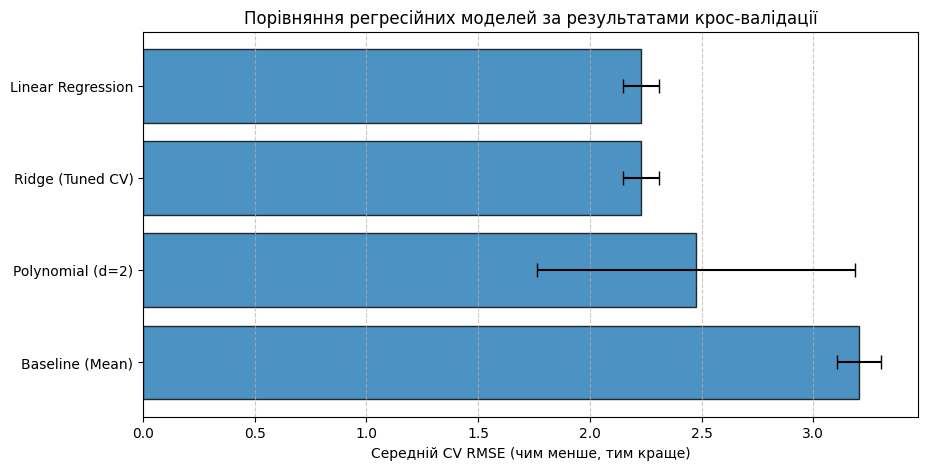

In [3]:
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, RidgeCV
from sklearn.preprocessing import PolynomialFeatures
from sklearn.model_selection import KFold, cross_val_score
import matplotlib.pyplot as plt

# 1. Фіксуємо схему крос-валідації (k=5)
cv = KFold(n_splits=5, shuffle=True, random_state=42)

# 2. Формуємо Pipeline для кожної моделі
models = {
    'Baseline (Mean)': Pipeline(steps=[
        ('prep', preprocessor), 
        ('model', DummyRegressor(strategy='mean'))
    ]),
    
    'Linear Regression': Pipeline(steps=[
        ('prep', preprocessor), 
        ('model', LinearRegression())
    ]),
    
    'Polynomial (d=2)': Pipeline(steps=[
        ('prep', preprocessor), 
        ('poly', PolynomialFeatures(degree=2, include_bias=False)),
        ('model', LinearRegression())
    ]),
    
    'Ridge (Tuned CV)': Pipeline(steps=[
        ('prep', preprocessor), 
        # Підбираємо alpha автоматично, що вирішує попередні методичні зауваження
        ('model', RidgeCV(alphas=[0.1, 1.0, 10.0, 100.0])) 
    ])
}

# 3. Виконання Cross-validation
cv_results = []
print("=== Результати 5-fold Cross-Validation (RMSE) ===")

for name, model in models.items():
    # Використовуємо neg_root_mean_squared_error для прямого отримання RMSE
    scores = cross_val_score(
        model, X_train, y_train, 
        cv=cv, scoring='neg_root_mean_squared_error', n_jobs=-1
    )
    rmse_scores = -scores # Робимо значення додатніми
    
    mean_rmse = rmse_scores.mean()
    std_rmse = rmse_scores.std()
    
    cv_results.append({
        'Модель': name,
        'Mean RMSE': mean_rmse,
        'Std RMSE': std_rmse
    })
    
    print(f"{name:20s}: {mean_rmse:.4f} ± {std_rmse:.4f}")

# 4. Формування таблиці та побудова графіка (Порівняння моделей)
results_df = pd.DataFrame(cv_results).sort_values(by='Mean RMSE', ascending=False)

plt.figure(figsize=(10, 5))
plt.barh(
    results_df['Модель'], 
    results_df['Mean RMSE'], 
    xerr=results_df['Std RMSE'], 
    color='#1f77b4', 
    capsize=5, 
    edgecolor='black',
    alpha=0.8
)
plt.xlabel('Середній CV RMSE (чим менше, тим краще)')
plt.title('Порівняння регресійних моделей за результатами крос-валідації')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.show()

=== Фінальне оцінювання на Test Set ===
MAE  : 1.5933
RMSE : 2.2116
R^2  : 0.5482

=== Порівняння CV та Test ===
RMSE_CV   : 2.2285
RMSE_test : 2.2116


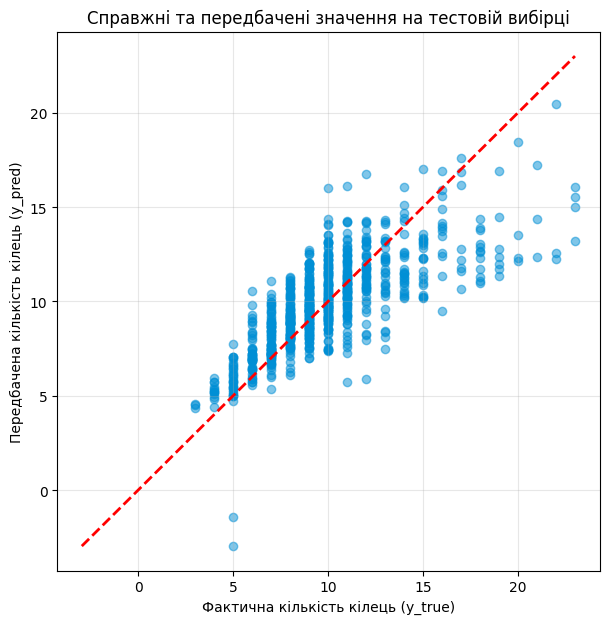

In [4]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Навчання фінальної моделі на всій навчальній вибірці
final_model = models['Ridge (Tuned CV)']
final_model.fit(X_train, y_train)

# 2. ОДИН РАЗ виконуємо прогнозування на незалежній тестовій вибірці
y_pred = final_model.predict(X_test)

# 3. Обчислення метрик
mae_test = mean_absolute_error(y_test, y_pred)
rmse_test = np.sqrt(mean_squared_error(y_test, y_pred))
r2_test = r2_score(y_test, y_pred)

print("=== Фінальне оцінювання на Test Set ===")
print(f"MAE  : {mae_test:.4f}")
print(f"RMSE : {rmse_test:.4f}")
print(f"R^2  : {r2_test:.4f}")

# Для порівняння метрик
print("\n=== Порівняння CV та Test ===")
print(f"RMSE_CV   : 2.2285")
print(f"RMSE_test : {rmse_test:.4f}")

# 4. Графік фактичних та передбачених значень
plt.figure(figsize=(7, 7))
plt.scatter(y_test, y_pred, alpha=0.5, color='#008fd5')

# Побудова ідеальної діагоналі y = x
min_val = min(y_test.min(), y_pred.min())
max_val = max(y_test.max(), y_pred.max())
plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', linewidth=2)

plt.xlabel('Фактична кількість кілець (y_true)')
plt.ylabel('Передбачена кількість кілець (y_pred)')
plt.title('Справжні та передбачені значення на тестовій вибірці')
plt.grid(alpha=0.3)
plt.show()